# Member 1 - Housing dataset and EDA
**Original contributor:** Mostafa. **Dataset H5:** [DOB NOW Build Job Application Filings](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd).

We study application activity, not completed homes. The full 2022-2025 filing window is used, not a row-limited sample. This revised notebook fixes the earlier unit double-counting and uses the building `postcode` field now verified in the live API. `zip` remains the owner's mailing ZIP and is never a building-location key.

Run Member 2's cleaning section first (its row-level CSV is also committed). Member 3 alone writes the final integrated CSV. Helpers contain the tested cleaning logic; all decisions and results are visible here.

## 1. Environment and reproducible paths
Resolve files from the repository, without creating duplicate data folders inside notebooks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "members").is_dir(), "Run from the repository root or notebooks directory."
CLEAN_DIR = ROOT / "data" / "clean"
RAW_DIR = ROOT / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "members" / "member1_housing"))
sys.path.insert(0, str(ROOT / "members" / "member3_integration"))
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.max_columns", 50)

## 2. Source, columns and complete-window download
The API has geography (`borough`, `postcode`, latitude/longitude), time (`filing_date`), identity (`job_filing_number`), building measures, cost and `job_type`. It also contains many personal/administrative fields that are not needed.

The downloader explicitly selects analysis columns, filters 2022-2025, pages in stable ID order, and checks its row count against the server count. A cached raw CSV is used explicitly, never as a hidden fallback after a failed download. Delete it to request a refresh; a companion JSON records provenance. Missing required fields fail with a clear error.

In [2]:
from fetch_h5_data import main as download_housing
housing_raw_path = RAW_DIR / "w9ak-ipjd.csv"
if not housing_raw_path.exists():
    download_housing()
print(f"Reading explicit raw cache: {housing_raw_path}")
df_raw = pd.read_csv(housing_raw_path, low_memory=False)
print(f"Raw shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
display(df_raw.head())
display(df_raw.dtypes.to_frame("dtype"))

Reading explicit raw cache: C:\Users\t-pnassef\OneDrive - Microsoft\Desktop\nyc-housing-transport\data\raw\w9ak-ipjd.csv


Raw shape: 598,706 rows x 38 columns


,job_filing_number,filing_date,filing_status,borough,block,lot,bin,commmunity_board,house_no,street_name,zip,building_type,initial_cost,total_construction_floor_area,existing_stories,existing_height,existing_dwelling_units,proposed_no_of_stories,proposed_height,proposed_dwelling_units,latitude,longitude,council_district,census_tract,nta,first_permit_date,approved_date,current_status_date,work_on_floor,apt_condo_no_s,special_inspection_agency_number,signoff_date,built_1_information_value,built_2_information_value,built_2_a_information_value,built_2_b_information_value,postcode,job_type
0,B00244768-P3,2022-05-18T00:00:00.000,Approved,Brooklyn,1987,21,3057064,303.0,22,MONROE STREET,11101,2 Family,12500.0,1734.0,NaN,NaN,2.0,NaN,NaN,2.0,40.684585,-73.958175,36.0,229.0,Bedford-Stuyvesant (West),NaN,2022-06-02T13:28:51.000,2022-06-02T17:28:54.000,"Cellar, Floor Number(s) 2 through 3, Floor Num...","Apr A, Apt B",001310,NaN,NaN,NaN,NaN,NaN,11238.0,Alteration
1,B00464221-S2,2023-11-11T00:00:00.000,Permit Entire,Brooklyn,1566,4,3042533,316.0,29,MARCONI PLACE,11435,2 Family,0.0,1456.0,2.0,24.0,2.0,2.0,24.0,2.0,40.676822,-73.912718,41.0,301.0,Ocean Hill,2025-09-12T00:00:00.000,2023-11-13T15:26:00.000,2025-09-12T19:20:57.000,"Cellar, Floor Number(s) 2 through 2",NaN,004288,NaN,NaN,NaN,NaN,NaN,11233.0,Alteration
2,B00451661-P2,2023-12-26T00:00:00.000,Approved,Brooklyn,1904,36,3054870,302.0,164,HALL STREET,18064,3 Family,77500.0,400.0,NaN,NaN,3.0,NaN,NaN,3.0,40.692927,-73.965814,35.0,195.0,Clinton Hill,NaN,2024-01-02T23:15:25.000,2024-01-03T04:15:25.000,"Basement/Sub-basement, Floor Number(s) 1 throu...",NaN,000930,NaN,NaN,NaN,NaN,NaN,11205.0,Alteration
3,B00461532-P2,2023-11-21T00:00:00.000,Approved,Brooklyn,1452,66,3413799,316.0,1481,ST MARKS AVENUE,11040,Other,5500.0,1.0,NaN,NaN,77.0,NaN,NaN,77.0,40.673494,-73.918516,41.0,303.0,Ocean Hill,NaN,2023-11-22T11:28:12.000,2023-11-22T16:28:13.000,Open Space,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11233.0,Alteration
4,B00360987-P2,2023-01-03T00:00:00.000,Approved,Brooklyn,2989,32,3070595,301.0,53,SCOTT AVENUE,76262,Other,100000.0,23825.0,NaN,NaN,0.0,NaN,NaN,0.0,40.709520,-73.922576,34.0,44902.0,East Williamsburg,NaN,2023-01-17T15:17:56.000,2023-01-18T16:16:44.000,"Floor Number(s) 001 through 005, Roof",NaN,1688,NaN,NaN,NaN,NaN,NaN,11237.0,Alteration


,dtype
job_filing_number,str
filing_date,str
filing_status,str
borough,str
block,int64
lot,int64
bin,int64
commmunity_board,float64
house_no,str
street_name,str


## 3. EDA: missing values, duplicates and distributions
Inspect the observed data rather than copying percentages from an older sample. Count duplicate filing IDs separately from exact duplicate rows.

,missing_count,missing_share
job_filing_number,0,0.000000
filing_date,0,0.000000
filing_status,0,0.000000
borough,0,0.000000
block,0,0.000000
lot,0,0.000000
bin,0,0.000000
commmunity_board,3941,0.006583
house_no,0,0.000000
street_name,0,0.000000


Exact duplicate rows: 0
Duplicate filing IDs: 55


,count,mean,std,min,25%,50%,75%,max
block,598706.0,3.088087e+03,3.194920e+03,0.000000,9.240000e+02,1.829000e+03,4.526000e+03,9.999900e+04
lot,598706.0,7.906939e+02,2.241598e+03,1.000000,1.200000e+01,3.300000e+01,6.400000e+01,9.999000e+03
bin,598706.0,2.574105e+06,1.386049e+06,18.000000,1.056607e+06,3.012564e+06,3.801522e+06,5.870943e+06
commmunity_board,594765.0,2.508984e+02,1.313866e+02,101.000000,1.070000e+02,3.010000e+02,3.180000e+02,7.502000e+03
initial_cost,598706.0,2.738680e+05,3.665480e+06,0.000000,5.000000e+03,2.500000e+04,9.500000e+04,8.000100e+08
total_construction_floor_area,556180.0,2.284988e+04,1.306097e+06,0.000000,5.000000e+02,1.940000e+03,5.608750e+03,7.700100e+08
existing_stories,263235.0,1.260365e+01,4.154391e+02,0.000000,2.000000e+00,4.000000e+00,1.000000e+01,9.250100e+04
existing_height,247561.0,1.170319e+02,3.266081e+03,0.000000,2.600000e+01,4.400000e+01,1.080000e+02,7.962650e+05
existing_dwelling_units,512658.0,2.599801e+02,1.551873e+05,0.000000,0.000000e+00,2.000000e+00,2.000000e+01,1.111111e+08
proposed_no_of_stories,298357.0,1.221351e+01,3.961840e+02,0.000000,2.000000e+00,4.000000e+00,9.000000e+00,9.250100e+04


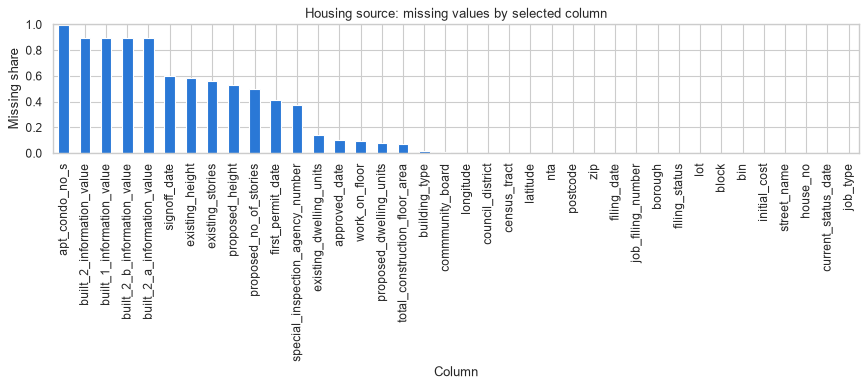

In [3]:
missing = df_raw.isna().mean().sort_values(ascending=False)
display(pd.DataFrame({"missing_count": df_raw.isna().sum(), "missing_share": df_raw.isna().mean()}))
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate filing IDs:", df_raw.duplicated("job_filing_number").sum())
display(df_raw.select_dtypes(include="number").describe().T)
fig, ax = plt.subplots(figsize=(11, 5))
missing.plot.bar(ax=ax, color="#2a78d6")
ax.set(title="Housing source: missing values by selected column", xlabel="Column", ylabel="Missing share")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

### Initial geography, time and outliers
A log-scaled cost distribution makes the long right tail readable; it is not evidence that every expensive project is erroneous.

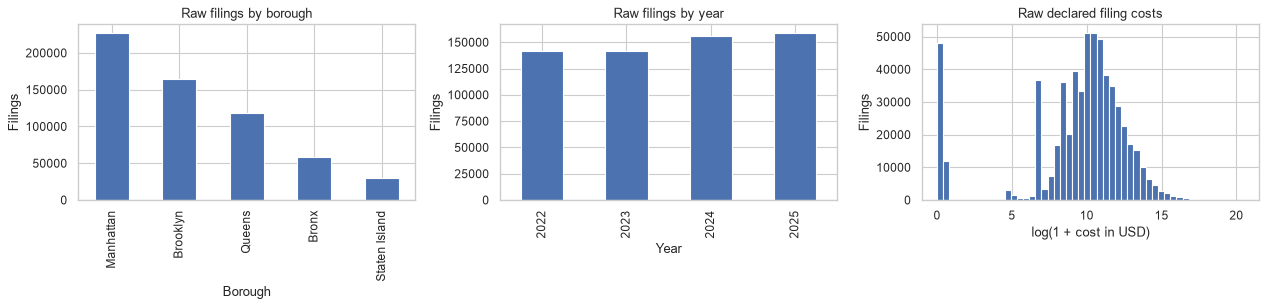

In [4]:
dates = pd.to_datetime(df_raw["filing_date"], format="mixed", errors="coerce")
raw_cost = pd.to_numeric(df_raw["initial_cost"], errors="coerce")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df_raw["borough"].value_counts().plot.bar(ax=axes[0])
axes[0].set(title="Raw filings by borough", xlabel="Borough", ylabel="Filings")
dates.dt.year.value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set(title="Raw filings by year", xlabel="Year", ylabel="Filings")
axes[2].hist(np.log1p(raw_cost[raw_cost >= 0]), bins=50)
axes[2].set(title="Raw declared filing costs", xlabel="log(1 + cost in USD)", ylabel="Filings")
plt.tight_layout()
plt.show()

## 4. Pre-integration cleaning: drop versus impute
1. **Drop** completely empty rows, unusable filing IDs, invalid dates/out-of-window years and invalid boroughs: these cannot be assigned reliable integration keys. Keep the latest status snapshot per filing ID. Drop borough/job-prefix conflicts because their location is ambiguous.
2. **Drop optional columns above 60% missing**, while protecting analysis fields even if sparse. No invented heights, units or costs.
3. **Keep the filing, quarantine the measure:** negative costs/areas, heights outside 0-2,000 feet, stories outside 0-150, and non-integer/negative dwelling units become missing. Unit values over **10,000 per job** are a conservative screening rule, not a verified correction; they become missing for review. In particular, a repeated-digit value such as 111,111,111 cannot dominate housing totals. Large plausible costs/areas/units remain and receive log-scale IQR flags.
4. **Missing existing units are not zero.** A blank does not prove a new building. Use the actual `job_type == "New Building"` label for new-building filing counts.
5. **Official building `postcode` first.** For missing/invalid postcode only, use the existing nearest-SIRTA-crash ZIP method within 0.01 degrees and flag it `nearest_crash`. This distance is approximate and is not an official boundary lookup. Invalid coordinates become missing. Drop rows only if neither method supplies a ZIP. The owner `zip` is never used.

The table below reports the actual rows and decisions. Geographic ZIP validity uses a broad NYC numeric screening range, not a USPS directory. Nearest-crash assignments may create coverage bias and boundary error; no unverified percentage is treated as measured accuracy.

In [5]:
from housing_pipeline import clean_housing, aggregate_housing
df_housing, cleaning_log = clean_housing(df_raw, CLEAN_DIR / "transport_clean_row_level.csv")
display(cleaning_log)
display(df_housing["zip_assignment_method"].value_counts().to_frame("filings"))
display(df_housing[["unit_value_quarantined", "outlier_flag"]].sum().to_frame("filings"))

ZIP assigned to 20.4% of filings (673 left missing).


,step,rows,note
0,Raw,598706,"Complete 2022-2025 download, not a row-limited..."
1,Keys and duplicates,598631,Drop invalid IDs/dates/boroughs; keep latest s...
2,Sparse optional columns,598631,Drop >60% missing optional columns: ['apt_cond...
3,Invalid measures,598631,Keep filings; set impossible measures to NaN. ...
4,Location consistency,598607,Drop borough/job-prefix conflicts; invalid coo...
5,Building ZIP,597934,Official postcode first; 173 flagged approxima...
6,Outliers,597934,Keep high but plausible values and flag using ...


,filings
zip_assignment_method,
official_postcode,597761
nearest_crash,173


,filings
unit_value_quarantined,22
outlier_flag,12162


## 5. Cleaning validation
Compare before/after counts and unit distributions. Keep extreme plausible projects visible, and confirm the filing key and location formats.

,metric,before,after
0,Rows,598706,597934
1,Duplicate filing IDs,55,0
2,Missing proposed units,48703,48662


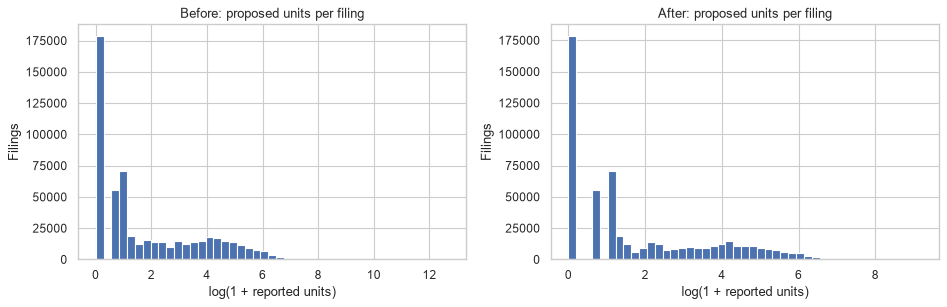

In [6]:
display(pd.DataFrame({
    "metric": ["Rows", "Duplicate filing IDs", "Missing proposed units"],
    "before": [len(df_raw), df_raw.duplicated("job_filing_number").sum(), df_raw["proposed_dwelling_units"].isna().sum()],
    "after": [len(df_housing), df_housing.duplicated("job_filing_number").sum(), df_housing["proposed_dwelling_units"].isna().sum()],
}))
assert not df_housing["job_filing_number"].duplicated().any()
assert df_housing["zip_code"].str.fullmatch(r"\d{5}").all()
assert df_housing["year"].isin([2022, 2023, 2024, 2025]).all()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, data, label in [(axes[0], df_raw, "Before"), (axes[1], df_housing, "After")]:
    values = pd.to_numeric(data["proposed_dwelling_units"], errors="coerce").dropna()
    ax.hist(values.clip(lower=0).pipe(np.log1p), bins=45)
    ax.set(title=f"{label}: proposed units per filing", xlabel="log(1 + reported units)", ylabel="Filings")
plt.tight_layout()
plt.show()

## 6. Aggregate to ZIP code x year without double-counting jobs
`filing_count` counts distinct filing IDs, including amendments. Unit totals must not count the same building-unit report once for every amendment.

Extract the base `job_id` before the filing suffix. Each job contributes **one complete existing/proposed unit pair**, taken from its latest valid filing in this window. Attribute that pair to the ZIP and year of its **first observed filing in 2022-2025**. This is a window-defined job cohort, not necessarily its original lifetime filing year. A job with no complete pair remains unknown; we do not borrow one side from another filing or invent zero units. Negative net changes are allowed.

`unique_job_count` and `jobs_with_known_units` reveal coverage. ZIP-years with no first-observed jobs have zero cohort units; if jobs exist but none report a complete pair, totals stay missing. Partial sums cover reporting jobs only. These are reported job/building-unit quantities, **not completed housing supply**. The four-year job totals can be summed without counting a job twice.

Declared cost and floor-area totals remain **filing-level reported amounts**, which may overlap across related filings; they are not a unique investment total. Official/approximate ZIP counts remain available for sensitivity checks.

In [7]:
df_housing_agg, housing_jobs = aggregate_housing(df_housing)
assert df_housing_agg["filing_count"].sum() == len(df_housing)
assert df_housing_agg["unique_job_count"].sum() == df_housing["job_id"].nunique()
assert df_housing_agg["official_zip_filings"].add(df_housing_agg["approximate_zip_filings"]).equals(df_housing_agg["filing_count"])
df_housing.to_csv(CLEAN_DIR / "housing_clean_row_level.csv", index=False)
df_housing_agg.to_csv(CLEAN_DIR / "housing_clean.csv", index=False)
print(f"Saved housing_clean.csv: {len(df_housing_agg):,} ZIP-years, {df_housing_agg.shape[1]} columns")
print(f"Unique jobs: {len(housing_jobs):,}; complete reported unit pairs: {housing_jobs['proposed_dwelling_units'].notna().sum():,}")
display(df_housing_agg.head())
display(df_housing_agg.dtypes.to_frame("dtype"))

Saved housing_clean.csv: 877 ZIP-years, 23 columns
Unique jobs: 346,294; complete reported unit pairs: 298,176


,zip_code,year,borough,filing_count,new_construction_filings,permit_issued_count,initial_cost_total,initial_cost_median,total_floor_area,avg_proposed_stories,avg_proposed_height,avg_latitude,avg_longitude,outlier_filing_count,outlier_filing_share,official_zip_filings,approximate_zip_filings,unique_job_count,jobs_with_known_units,proposed_units_total,existing_units_total,net_new_units,is_outlier_zip_year
0,10001,2022,MANHATTAN,2659,9,1260,1.118761e+09,25000.00,9.350611e+07,22.886898,288.375479,40.749995,-73.995301,93,0.034976,2659,0,2182,1939,103971.0,96716.0,7255.0,True
1,10001,2023,MANHATTAN,2567,18,1124,1.762834e+09,34999.44,6.568540e+07,25.262959,353.155556,40.750120,-73.995315,93,0.036229,2567,0,1641,1392,71383.0,70768.0,615.0,True
2,10001,2024,MANHATTAN,2650,8,1201,1.146879e+09,38748.50,5.963017e+07,31.220197,461.863192,40.750026,-73.995652,64,0.024151,2650,0,1469,1188,42551.0,41235.0,1316.0,True
3,10001,2025,MANHATTAN,2532,33,833,1.210055e+09,36750.00,4.061151e+07,25.937788,369.956911,40.749856,-73.995030,45,0.017773,2532,0,1372,1107,42749.0,41515.0,1234.0,True
4,10002,2022,MANHATTAN,1334,35,598,3.446611e+08,17500.00,1.192265e+08,10.789077,105.637450,40.717120,-73.988388,66,0.049475,1334,0,1050,996,96736.0,93937.0,2799.0,False


,dtype
zip_code,str
year,int64
borough,string
filing_count,int64
new_construction_filings,Int64
permit_issued_count,int64
initial_cost_total,float64
initial_cost_median,float64
total_floor_area,float64
avg_proposed_stories,float64


## 7. Two research questions and two visualizations
For this member's exploratory charts only, merge the corrected housing aggregate with transportation **in memory**. Never overwrite Member 3's final integrated CSV. Housing-only rows have zero recorded serious crashes under the same coverage assumption documented by Member 3.

### RQ1. How does reported net unit change among first-observed jobs vary by borough and cohort year?
A diverging heatmap distinguishes reported increases from decreases. It does not show homes built.

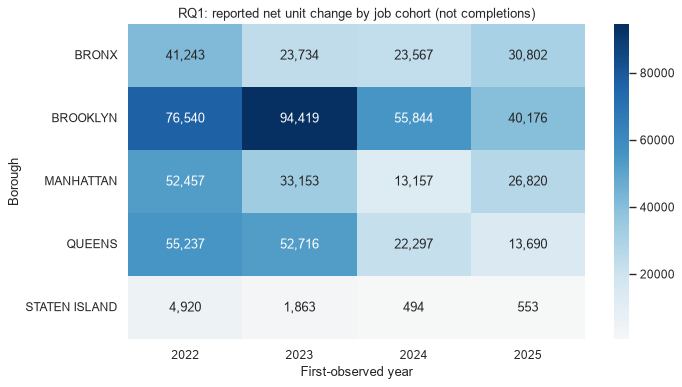

**Finding:** reporting jobs show net change of **663,682 units** across the window. Only **298,176 of 346,294 jobs** have a complete pair. Read the borough-year cells alongside this coverage; incomplete reporting prevents a total-supply claim.

In [8]:
transport_for_housing = pd.read_csv(CLEAN_DIR / "transport_clean.csv", dtype={"zip_code": str})
housing_analysis = df_housing_agg.merge(
    transport_for_housing[["zip_code", "year", "crash_count"]],
    on=["zip_code", "year"], how="left", validate="one_to_one")
housing_analysis["crash_count"] = housing_analysis["crash_count"].fillna(0)
unit_story = (housing_analysis.groupby(["borough", "year"])["net_new_units"]
              .sum(min_count=1).unstack())
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(unit_story, annot=True, fmt=",.0f", center=0, cmap="RdBu", ax=ax)
ax.set(title="RQ1: reported net unit change by job cohort (not completions)", xlabel="First-observed year", ylabel="Borough")
plt.tight_layout()
plt.show()
known = int(housing_jobs["proposed_dwelling_units"].notna().sum())
display(Markdown(f"**Finding:** reporting jobs show net change of **{housing_jobs['net_new_units'].sum():,.0f} units** across the window. "
                 f"Only **{known:,} of {len(housing_jobs):,} jobs** have a complete pair. "
                 "Read the borough-year cells alongside this coverage; incomplete reporting prevents a total-supply claim."))

### RQ2. Are ZIP-years with more housing filings also those with more recorded serious crashes?
A scatter plot shows both counts without treating filings as completed construction. Repeated ZIP-years are not independent; report descriptive correlation rather than an inferential p-value.

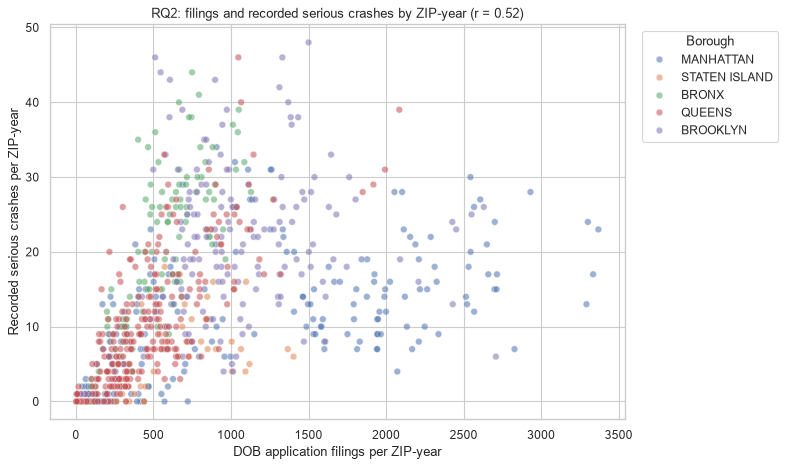

**Finding:** the pooled descriptive Pearson correlation is **0.52**. This compares places of different size and activity. It cannot show that filings cause crashes. Member 3 separately checks changes within places and a one-year lag.

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=housing_analysis, x="filing_count", y="crash_count", hue="borough", alpha=0.55, ax=ax)
housing_r = housing_analysis["filing_count"].corr(housing_analysis["crash_count"])
ax.set(title=f"RQ2: filings and recorded serious crashes by ZIP-year (r = {housing_r:.2f})",
       xlabel="DOB application filings per ZIP-year", ylabel="Recorded serious crashes per ZIP-year")
ax.legend(title="Borough", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
display(Markdown(f"**Finding:** the pooled descriptive Pearson correlation is **{housing_r:.2f}**. "
                 "This compares places of different size and activity. It cannot show that filings cause crashes. "
                 "Member 3 separately checks changes within places and a one-year lag."))

## 8. Provenance, limitations and contribution
Sources: [H5 housing](https://data.cityofnewyork.us/resource/w9ak-ipjd.json), [T4 SIRTA](https://data.cityofnewyork.us/resource/xeqp-qz8h.json).

Limitations: mutable source snapshots; missing unit pairs; cohort attribution is first observed within this window, not lifetime start; filings and reported units are not completions; approximate ZIP fallback can misclassify boundaries and preferentially cover crash locations; no population/traffic exposure; serious-crash coverage only; correlation is not causation.

Member 1 provides housing EDA, justified cleaning, job-aware unit accounting and two charts. AI-assisted correction and validation are recorded in `docs/prompts.md`; original team members should review the regenerated results before submission.